In [1]:
from google.colab import drive
drive.mount('/content/drive')
# monta o Google Drive, onde ficam os dados processados e os modelos

Mounted at /content/drive


In [2]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D, concatenate, Conv2DTranspose, BatchNormalization, Dropout, Lambda, ReLU
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Activation, MaxPool2D, Concatenate
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, TensorBoard, ReduceLROnPlateau
import numpy as np
from tensorflow.keras.metrics import MeanIoU

In [3]:
# hiper parametros
height_img = 288
width_img = 288
canais = 3
epochs = 50
batch_size = 16
lr = 0.0001

In [4]:
# carregando os dados de treino e validação
x_train = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/x_train.npy')
y_train = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/y_train.npy')
x_val = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/x_val.npy')
y_val = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/y_val.npy')

### Para facilitar a conexão entre as camadas convolucionais, encoder e decoders, separei em funções onde no final serão chamadas para a composiçãoo do modelo final

In [5]:
def convolucao(input, filters):
  x = Conv2D(filters,3, padding='same')(input)
  # Convolução de filters features maps que captura as principais informações da imagem
  x = BatchNormalization()(x)
  # normalização dos dados
  x = Activation('relu')(x)
  # função de ativação que subistui valores negativos por 0

#repetição da convolução
  x = Conv2D(filters,3, padding='same')(x)
  x = BatchNormalization()(x)
  x = Activation('relu')(x)

  return x

In [6]:
# o encoder vai realizar usar a convolução e diminuir gradativamente a dimensionalidade da imagem, pegando somente as caracteristicas essencias da imagem
def encoder(input,filters):
  x = convolucao(input,filters)
  # convolução
  p = MaxPool2D((2,2))(x)
  # vai diminuir a dimensionalidade pela metade
  return x, p

In [7]:
def decoder(input, skip_features, filters):
  # como o bloco encoder diminui a dimensionalidade pegando suas principais caracteristicas
  # o decoder vai fazer o contrário, vai aumentar a dimensionalidade com as caracteristicas aprendidas no encoder

  # Na arquitetura U-Net, para cada bloco decoder é pego como se fosse uma referencia de como era a imagem no bloco encoder
  # resumindo: para o decoder nao se perder ao classificar os pixels ele usa esse concatenate como referencia

  x = Conv2DTranspose(filters, (2,2), strides=2, padding='same')(input)

  x = Concatenate()([x, skip_features])
    # como dito antes, ira pegar como referencia o bloco encoder
  x = convolucao(x,filters)
  # convolucao
  return x

In [8]:
def modelo_unet(input_shape):
# chamando todas as funções e motando a arquitetura
  inputs = Input(input_shape)

    # o encoder como ele diminui a dimensionalidade e aumaneta o numero de feature maps
    # em s1 temos a convolução e em p o poll, retornos da função encoder
    # inputs vai ser o tamanho da imagem e canais
    # e na chamada do encoder terá a quantidade de filtros que cada camada utilizará na convolução
  s1,p1 = encoder(inputs, 64)
  s2,p2 = encoder(p1,128)
  s3,p3 = encoder(p2,256)
  s4,p4 = encoder(p3,512)

  b1 = convolucao(p4, 1024)
  # b1 é a convolução base da rede, após isso o decoder vai atuar

  # o decoder vai aumentar a dimensionalidade, entao vai diminuir o numero de feature maps e aumentar a dimensionalidade da imagem
  d1 = decoder(b1, s4,512)
  d2 = decoder(d1, s3, 256)
  d3 = decoder(d2, s2, 128)
  d4 = decoder(d3, s1, 64)

  outputs = Conv2D(5,1, padding='same', activation='softmax')(d4)
  # a funcao de ativação softmax retorna uma probabilidade para cada classe

  model = Model(inputs, outputs, name='U-Net_segmentation_rice')
  # cria o modelo
  return model

In [9]:
model = modelo_unet((height_img, width_img, canais))
# criando o modelo

In [10]:
model.compile(optimizer=Adam(learning_rate=lr), loss='sparse_categorical_crossentropy', metrics=[MeanIoU(num_classes=5, sparse_y_true=True, sparse_y_pred=False)])
# compilando o modelo com o otimizador Adam, a função de loss, e o MeanIoU como medida para avaliar o modelo durante o treino
# a acuracia estava muito alta pois o modelo pode prever totalmente o fundo pois é a classe majoritaria em todas as imagens, nisso apliquei a metrica MeanIoU e coloquei o sparse mostrar como o modelo dee agir para os valores reais(que nao sao One-Hot) e deve devolver probabilidades
# foi usado o sparse_categorical_crossentropy por conta dos dados rotulados estarem como numeros inteiros e nao em vetores one-hot(dai usaria o categorical_crossentropy)

In [11]:
model.summary()

Model: "U-Net_segmentation_rice"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 288, 288,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 288, 288,  │      1,792 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 288, 288,  │        256 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 288, 288,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 288, 288,  │     36,928 │ activation[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 288, 288,  │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 288, 288,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 144, 144,  │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 144, 144,  │     73,856 │ max_pooling2d[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 144, 144,  │        512 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 144, 144,  │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 144, 144,  │    147,584 │ activation_2[0][… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 144, 144,  │        512 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 144, 144,  │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 72, 72,    │          0 │ activation_3[0][… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 72, 72,    │    295,168 │ max_pooling2d_1[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 72, 72,    │      1,024 │ conv2d_4[0][0]  

 Total params: 31,055,557 (118.47 MB)

 Trainable params: 31,043,781 (118.42 MB)

 Non-trainable params: 11,776 (46.00 KB)

In [12]:
path_model = '/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/U-Net/modelo_unet.keras'

In [13]:
checkpointer = ModelCheckpoint(path_model, verbose=1, save_best_only=True, monitor='val_mean_io_u', mode='max')
# salva o melhor modelo alcançado durante o treino, medido pelo IoU
# quanto mais proximo de 1 melhor
early_stopper = EarlyStopping(patience = 8, monitor='val_loss')
# para o treino caso após 8 epocas o val_loss nao tenha melhorado
lr_reducer = ReduceLROnPlateau(monitor='val_loss', factor=0.3,patience=3, min_lr=0.000001, verbose=1)
# reduz o leanring rate se apos 3 epocas o val_loss nao apresentar melhoras
checks = [checkpointer, lr_reducer,early_stopper]

In [14]:
treino = model.fit(x_train, y_train,validation_data=(x_val, y_val),epochs=epochs,batch_size=batch_size,callbacks=checks)
# treinando o modelo

Epoch 1/50
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 694ms/step - loss: 0.6964 - mean_io_u: 0.2033
Epoch 1: val_mean_io_u improved from None to 0.18624, saving model to /content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/U-Net/modelo_unet.keras

Epoch 1: finished saving model to /content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/U-Net/modelo_unet.keras
297/297 ━━━━━━━━━━━━━━━━━━━━ 325s 810ms/step - loss: 0.4562 - mean_io_u: 0.2302 - val_loss: 9.8702 - val_mean_io_u: 0.1862 - learning_rate: 1.0000e-04
Epoch 2/50
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 538ms/step - loss: 0.2667 - mean_io_u: 0.2581
Epoch 2: val_mean_io_u improved from 0.18624 to 0.33768, saving model to /content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/U-Net/modelo_unet.keras

Epoch 2: finished saving model to /content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/U-Net/modelo_unet.keras
297/297 ━━━━━━━━━━━━━━━━━━━━ 172s 580ms/step - loss: 0.2431 - mean_io_u: 0

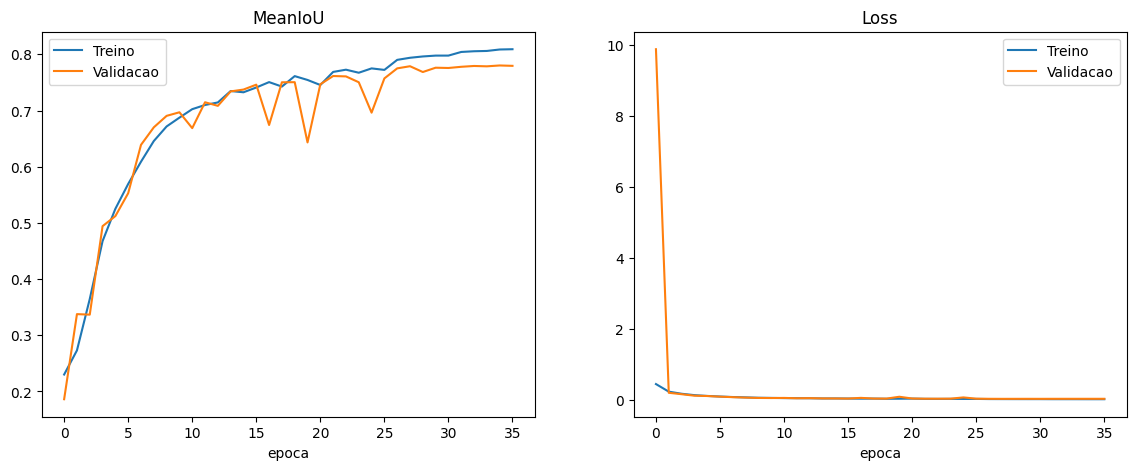

In [15]:
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(treino.history['mean_io_u'], label='Treino')
plt.plot(treino.history['val_mean_io_u'], label='Validacao')
plt.title('MeanIoU')
plt.xlabel('epoca')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(treino.history['loss'], label='Treino')
plt.plot(treino.history['val_loss'], label='Validacao')
plt.title('Loss')
plt.xlabel('epoca')
plt.legend()

plt.show()
